# P2 · Phân nhóm & tổng hợp — Bước 2–3 · 9

**Input (cell đầu tự nạp):** common/segment_labels.parquet, common/sample_ids.csv, data/processed/data_long.parquet

**Output (cell cuối tự lưu):** bảng EDA/khuyến nghị trong data/outputs/

**Code mẫu tham khảo:** `notebooks/M5_reference.ipynb` phần **§2**.

> Chạy được **cell đầu** (thấy `✅ Input sẵn sàng`) = đủ input để làm phần của bạn. Code ở khu vực giữa. Cuối cùng chạy **cell lưu output**.

## Cell đầu — import + nạp input (chạy được = sẵn sàng)

In [1]:
from pathlib import Path
def _need(p, hint):
    assert Path(p).exists(), f"THIẾU INPUT: {p}  →  {hint}"

import numpy as np, pandas as pd, yaml
import matplotlib.pyplot as plt
_need("common/config.yaml", "clone repo")
_need("common/segment_labels.parquet", "clone repo (P1 đã tạo)")
_need("common/sample_ids.csv", "clone repo (P1 đã tạo)")
_need("data/processed/data_long.parquet", "chạy P1.ipynb hoặc tải data_long P1 gửi vào data/processed/")
CFG = yaml.safe_load(open("common/config.yaml", encoding="utf-8"))
SEED = CFG["seed"]; SP = CFG["split"]; SBC = CFG["sbc"]; SAMP = CFG["sampling"]
ID_COLS = ["id","item_id","dept_id","cat_id","store_id","state_id"]

seg = pd.read_parquet("common/segment_labels.parquet")
sample_ids = pd.read_csv("common/sample_ids.csv")["series_id"].tolist()
long = pd.read_parquet("data/processed/data_long.parquet")
print("✅ Input sẵn sàng — long", long.shape, "| nhãn", seg.shape, "| mẫu", len(sample_ids))

✅ Input sẵn sàng — long (6743034, 24) | nhãn (30490, 5) | mẫu 3474


## Phần code chính — tự triển khai ở đây
(Thêm bao nhiêu cell tuỳ ý giữa cell input và cell lưu output.)

In [2]:
# ===== Bước 2–3: Tổng hợp phân nhóm demand (SBC) — trên toàn bộ 30.490 chuỗi =====
# segment_labels (P1) đã có sẵn ADI / CV² / zero_rate / segment; P2 chỉ tổng hợp, không tính lại.
order = ["smooth", "erratic", "intermittent", "lumpy"]
summary = (seg.groupby("segment")
             .agg(n_series=("series_id", "size"),
                  zero_rate=("zero_rate", "mean"),
                  ADI=("ADI", "median"),
                  CV2=("CV2", "median"))
             .reindex(order))
summary["pct"] = (summary["n_series"] / summary["n_series"].sum() * 100).round(2)
summary = summary.reset_index()
print("Phân bố 4 nhóm demand:")
print(summary.round(3).to_string(index=False))

Phân bố 4 nhóm demand:
     segment  n_series  zero_rate   ADI   CV2   pct
      smooth       980      0.138 1.177 0.374  3.21
     erratic       494      0.167 1.216 0.614  1.62
intermittent     23095      0.738 4.598 0.298 75.75
       lumpy      5921      0.604 2.503 0.619 19.42


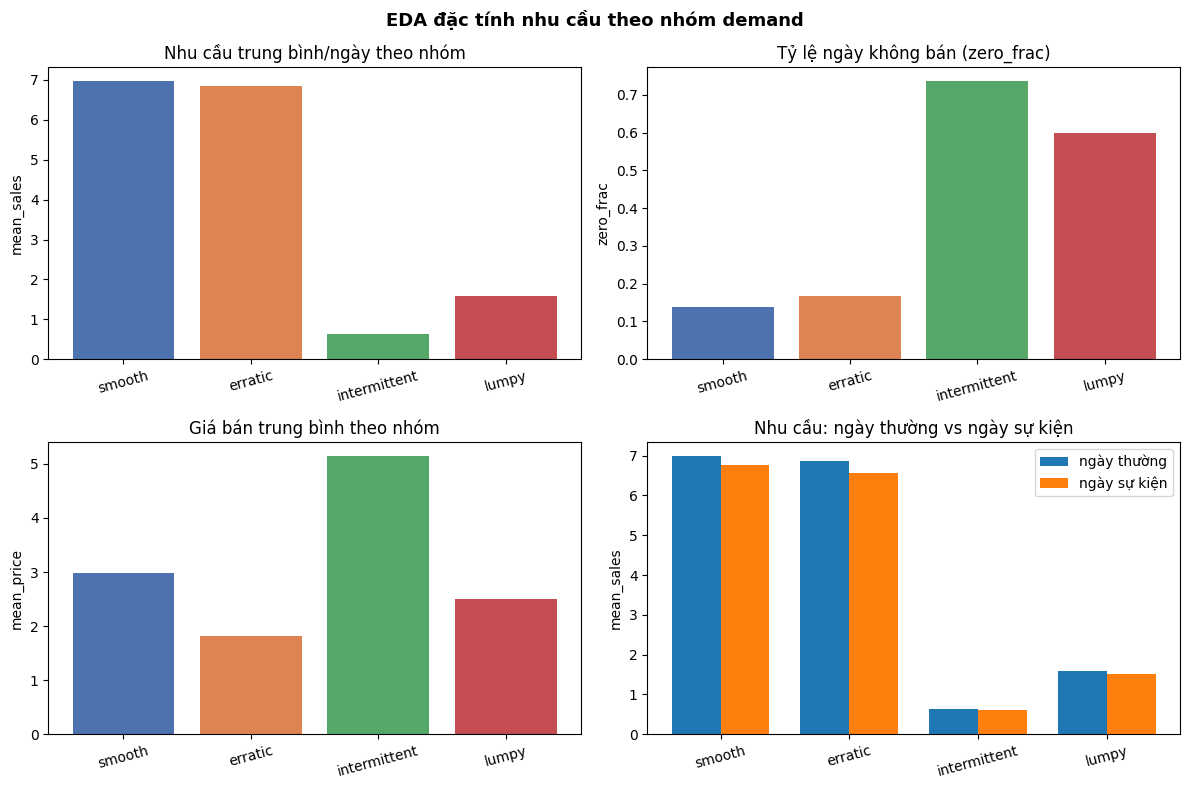

In [3]:
# ===== EDA nhu cầu theo nhóm (trên mẫu data_long 3.474 chuỗi) — trình bày bằng biểu đồ =====
%matplotlib inline
demand = (long.groupby("segment")
              .agg(mean_sales=("sales", "mean"),
                   zero_frac=("sales", lambda s: float((s == 0).mean())),
                   mean_price=("sell_price", "mean"))
              .reindex(order))
# Nhu cầu trung bình ngày có sự kiện vs ngày thường
ev = (long.groupby(["segment", "is_event"])["sales"].mean()
          .unstack("is_event")
          .rename(columns={0: "sales_non_event", 1: "sales_event"})
          .reindex(order))
demand = demand.join(ev).reset_index()

colors = ["#4C72B0", "#DD8452", "#55A868", "#C44E52"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].bar(demand["segment"], demand["mean_sales"], color=colors)
axes[0, 0].set_title("Nhu cầu trung bình/ngày theo nhóm")
axes[0, 0].set_ylabel("mean_sales")

axes[0, 1].bar(demand["segment"], demand["zero_frac"], color=colors)
axes[0, 1].set_title("Tỷ lệ ngày không bán (zero_frac)")
axes[0, 1].set_ylabel("zero_frac")

axes[1, 0].bar(demand["segment"], demand["mean_price"], color=colors)
axes[1, 0].set_title("Giá bán trung bình theo nhóm")
axes[1, 0].set_ylabel("mean_price")

x = np.arange(len(demand)); w = 0.38
axes[1, 1].bar(x - w / 2, demand["sales_non_event"], w, label="ngày thường")
axes[1, 1].bar(x + w / 2, demand["sales_event"], w, label="ngày sự kiện")
axes[1, 1].set_xticks(x); axes[1, 1].set_xticklabels(demand["segment"])
axes[1, 1].set_title("Nhu cầu: ngày thường vs ngày sự kiện")
axes[1, 1].set_ylabel("mean_sales"); axes[1, 1].legend()

for ax in axes.flat:
    ax.tick_params(axis="x", rotation=15)
fig.suptitle("EDA đặc tính nhu cầu theo nhóm demand", fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

In [4]:
# ===== Bước 9: Bảng khuyến nghị model theo nhóm (dựa trên kết quả P5) =====
_need("data/outputs/metrics_by_model_segment.parquet", "cần P5 chạy xong — git pull lấy forecasts + metrics")
_need("data/outputs/decision_table.parquet", "cần P5 chạy xong — git pull")
metrics = pd.read_parquet("data/outputs/metrics_by_model_segment.parquet")
decision = pd.read_parquet("data/outputs/decision_table.parquet").rename(columns={
    "Nhóm demand": "segment",
    "Nên dùng (SPL)": "recommended_model",
    "Độ tin cậy": "confidence",
    "Chênh vs á quân (%)": "margin_pct"})
# Đính kèm SPL/WSPL của model được chọn + số chuỗi mỗi nhóm
chosen = metrics.merge(decision[["segment", "recommended_model"]],
                       left_on=["segment", "model"],
                       right_on=["segment", "recommended_model"])
recommendation = (decision
                  .merge(chosen[["segment", "SPL", "WSPL"]], on="segment", how="left")
                  .merge(summary[["segment", "n_series", "pct"]], on="segment", how="left")
                  .set_index("segment").reindex(order).reset_index())
print("Khuyến nghị model theo nhóm demand:")
print(recommendation.round(3).to_string(index=False))

Khuyến nghị model theo nhóm demand:
     segment recommended_model  confidence  margin_pct   SPL  WSPL  n_series   pct
      smooth              lgbm tương đương         2.1 0.177 0.184       980  3.21
     erratic      chronos_bolt tương đương         2.6 0.200 0.305       494  1.62
intermittent              lgbm tương đương         2.8 0.230 0.242     23095 75.75
       lumpy              lgbm    thắng rõ         6.4 0.238 0.259      5921 19.42


## Cell cuối — lưu output (điền biến theo comment rồi chạy)

In [5]:
# ===== Lưu output để P1 tổng hợp báo cáo =====
Path("data/outputs").mkdir(parents=True, exist_ok=True)
summary.to_parquet("data/outputs/p2_segment_summary.parquet", index=False)
demand.to_parquet("data/outputs/p2_demand_by_segment.parquet", index=False)
recommendation.to_parquet("data/outputs/p2_recommendation.parquet", index=False)
print("✅ Đã lưu p2_segment_summary / p2_demand_by_segment / p2_recommendation vào data/outputs/")

✅ Đã lưu p2_segment_summary / p2_demand_by_segment / p2_recommendation vào data/outputs/
